In [1]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [2]:
# Set path
path = 'drive/MyDrive/Colab Notebooks/Structural Biology/data'

import os
if os.path.exists(path +'/figures') is False:
  os.mkdir(path +'/figures')

In [3]:
!pip install biopython
!pip install scipy
!pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 11.6 MB/s eta 0:00:00


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
from Bio.PDB import PDBList, PDBParser
from Bio.SeqUtils import seq1

In [5]:
# import aa_list, p_matrix, m_matrix
execfile(path + "/iupred_data.py")

Биологически IUPred спрашивает: “может ли данный участок белка сформировать достаточно выгодных внутренних контактов, чтобы быть стабильной структурой?” Если локальный аминокислотный состав плохо поддерживает плотную сеть контактов, участок считается более склонным к intrinsic disorder. В официальном описании IUPred основан на energy estimation approach: энергия для остатка оценивается по типу аминокислоты и составу её последовательностного окружения через 20 × 20 матрицу, затем профиль сглаживается и в полной версии переводится в score от 0 до 1

In [ ]:
print(aa_list)

['A', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'P', 'Q', 'R', 'S', 'T', 'V', 'W', 'Y']


In [ ]:
print(m_matrix)

[[-0.2, -0.44, 0.16, 0.26, -0.46, -0.26, 0.5, -0.57, 0.1, -0.36, -0.22, 0.07, 0.14, 0.01, 0.2, -0.09, -0.05, -0.42, 0.05, -0.5], [-0.44, -2.99, 0.21, 0.19, -0.88, -0.34, -1.11, -0.36, 0.09, -0.53, -0.43, -0.52, -0.14, -0.43, -0.24, 0.13, -0.22, -0.62, 0.24, -0.79], [0.16, 0.21, 0.17, 0.55, 0.38, 0.35, -0.23, 0.44, 0.39, 0.28, 0.35, -0.02, 1.03, 0.49, -0.37, 0.19, -0.12, 0.69, 0.04, 0.43], [0.26, 0.19, 0.55, 0.6, 0.55, 0.65, 0.18, 0.37, 0.47, 0.33, 0.29, 0.01, 0.69, 0.04, -0.52, 0.18, 0.37, 0.39, 0.03, 0.17], [-0.46, -0.88, 0.38, 0.55, -0.94, 0.17, -0.4, -0.88, 0.01, -1.08, -0.78, 0.22, 0.2, 0.26, -0.19, -0.22, 0.02, -1.15, -0.6, -0.88], [-0.26, -0.34, 0.35, 0.65, 0.17, -0.12, 0.18, 0.24, 0.19, 0.24, 0.02, -0.04, 0.6, 0.46, 0.5, 0.28, 0.28, 0.27, 0.51, -0.35], [0.5, -1.11, -0.23, 0.18, -0.4, 0.18, 0.42, -0.0, 0.79, -0.24, -0.07, 0.2, 0.25, 0.69, 0.24, 0.21, 0.11, 0.16, -0.85, -0.26], [-0.57, -0.36, 0.44, 0.37, -0.88, 0.24, -0.0, -1.16, 0.15, -1.25, -0.58, -0.09, 0.36, -0.08, 0.14, 0.32,

In [ ]:
print(p_matrix)

[[-1.65, -2.83, 1.16, 1.8, -3.73, -0.41, 1.9, -3.69, 0.49, -3.01, -2.08, 0.66, 1.54, 1.2, 0.98, -0.08, 0.46, -2.31, 0.32, -4.62], [-2.83, -39.58, -0.82, -0.53, -3.07, -2.96, -4.98, 0.34, -1.38, -2.15, 1.43, -4.18, -2.13, -2.91, -0.41, -2.33, -1.84, -0.16, 4.26, -4.46], [1.16, -0.82, 0.84, 1.97, -0.92, 0.88, -1.07, 0.68, -1.93, 0.23, 0.61, 0.32, 3.31, 2.67, -2.02, 0.91, -0.65, 0.94, -0.71, 0.9], [1.8, -0.53, 1.97, 1.45, 0.94, 1.31, 0.61, 1.3, -2.51, 1.14, 2.53, 0.2, 1.44, 0.1, -3.13, 0.81, 1.54, 0.12, -1.07, 1.29], [-3.73, -3.07, -0.92, 0.94, -11.25, 0.35, -3.57, -5.88, -0.82, -8.59, -5.34, 0.73, 0.32, 0.77, -0.4, -2.22, 0.11, -7.05, -7.09, -8.8], [-0.41, -2.96, 0.88, 1.31, 0.35, -0.2, 1.09, -0.65, -0.16, -0.55, -0.52, -0.32, 2.25, 1.11, 0.84, 0.71, 0.59, -0.38, 1.69, -1.9], [1.9, -4.98, -1.07, 0.61, -3.57, 1.09, 1.97, -0.71, 2.89, -0.86, -0.75, 1.84, 0.35, 2.64, 2.05, 0.82, -0.01, 0.27, -7.58, -3.2], [-3.69, 0.34, 0.68, 1.3, -5.88, -0.65, -0.71, -6.74, -0.01, -9.01, -3.62, -0.07, 0.12,

IUpred implementation

Биологическая логика: значения около 0 означают нейтральный вклад, отрицательные значения обычно интерпретируются как более выгодные контакты, положительные как менее выгодные или destabilizing contribution. Поэтому удобно видеть, какие пары аминокислот дают “выгодные” или “невыгодные” энергетические вклады.

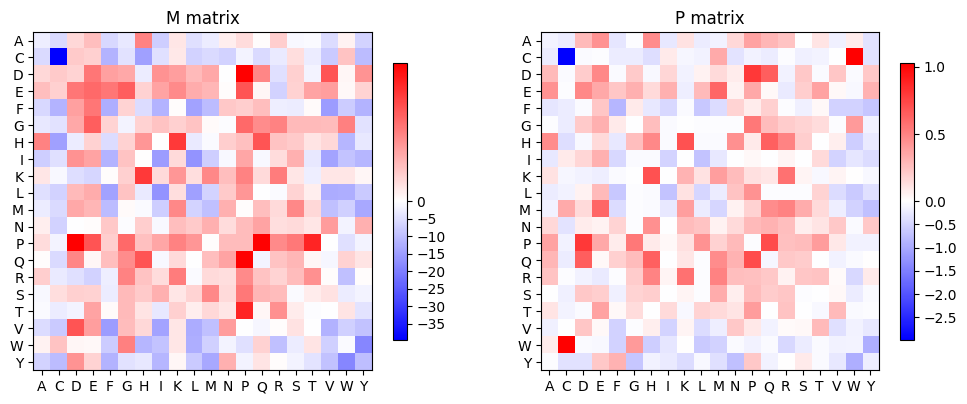

In [6]:
p_matrix = np.array(p_matrix)
m_matrix = np.array(m_matrix)

# Plot the M and P matrix
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# M matrix
divnorm = colors.TwoSlopeNorm(vmin=np.amin(m_matrix), vcenter=0.,
                              vmax=np.amax(m_matrix))  # center the colormap (white) to 0
img = axes[0].imshow(m_matrix, interpolation="none", cmap='bwr', norm=divnorm)
axes[0].set_title('M matrix')
axes[0].set_xticks([i for i, aa in enumerate(aa_list)])
axes[0].set_xticklabels(aa_list)
axes[0].set_yticks([i for i, aa in enumerate(aa_list)])
axes[0].set_yticklabels(aa_list)
fig.colorbar(img, ax=axes[1], shrink=0.6)

# P matrix
divnorm = colors.TwoSlopeNorm(vmin=np.amin(p_matrix), vcenter=0.,
                              vmax=np.amax(p_matrix))  # center the colormap (white) to 0
img = axes[1].imshow(p_matrix, interpolation="none", cmap='bwr', norm=divnorm)
axes[1].set_title('P matrix')
axes[1].set_xticks([i for i, aa in enumerate(aa_list)])
axes[1].set_xticklabels(aa_list)
axes[1].set_yticks([i for i, aa in enumerate(aa_list)])
axes[1].set_yticklabels(aa_list)
fig.colorbar(img, ax=axes[0], shrink=0.6)


plt.savefig(path + '/figures/iupred_matrix.png', dpi=300, bbox_inches='tight')

Параметры:

`sequence_separation=2`: не учитывать слишком близкие соседние аминокислоты.

`Почему`: соседние остатки рядом просто потому, что они соседние в цепи. Для folding/disorder интереснее дальние контакты, потому что стабильная структура формируется не только соседями по цепи, а сетью контактов между участками.

`window_size=100`: смотреть на окружение до 100 аминокислот влево и вправо.

`Почему`: disorder зависит не от одной аминокислоты, а от локального состава участка.

`window_size_smooth=5`: сгладить итоговый профиль.

`Почему`: одиночный residue-level сигнал шумный. Биологически disorder обычно идёт участками, а не одной аминокислотой.

In [7]:
def iupred(seq, sequence_separation=2, window_size=100, window_size_smooth=10):
    '''
    Calculate per residue IUPred energy considering windows_size neighbouring
    residues and applying a smoothing with a sliding window window_size_smooth
    long

    :param seq: a string of aminoacids
    :param sequence_separation: neighbours min distance
    :param window_size: neighbours max distance
    :param window_size_smooth: sliding window size
    :return: row prediction, smoothed prediction
    '''

    pred = []  # Calculated energy per sequence position
    pred_smooth = []

    indices = [aa_list.index(aa) for aa in list(seq)]  # Transform sequence into indexes as in the P matrix
    # print(indices)
    # return None, None

    for i, aa_index in enumerate(indices): #i=индекс в последовательности, aa_index=номер АК из p-matrix

        # Get the slice i-100/i+100 excluding adjacent positions (+/-1) исключая исслед позицию i и 2 самые ближние к ней
        start_before = max(0, i - window_size)
        end_before = max(0, i - sequence_separation)
        start_after = min(len(indices) - 1, i + sequence_separation + 1)
        end_after = min(len(indices) - 1, i + window_size + 1)
        indices_local = indices[start_before: end_before] + indices[start_after: end_after]
        # print(i, aa_index, aa_list[aa_index], len(indices), len(indices_local), start_before, end_before, start_after, end_after)

        # Count the different amino acids in the window
        '''
        Что делает: создаёт вектор длиной 20,
        где каждая позиция это количество одной аминокислоты в локальном окне.
        Пример: если в окне много A, P, S,
        то соответствующие позиции в row будут большими.
        '''
        row = np.full((20,), 0)
        for index in indices_local:
            row[index] += 1
        # print(row)

        # calculate AA frequency = превращает количество аминокислот в частоты
        row = row / len(indices_local)
        # print(row)

        # calculate energy = берёт строку p_matrix,
        # соответствующую текущей аминокислоте,
        # и умножает её на частоты аминокислот в окружении
        row = row * p_matrix[aa_index, ]
        # print(row)

        aa_energy = np.sum(row)
        # print(i, seq[i], aa_energy)
        '''
        energy(current residue) =
        frequency(A) * P[current, A] +
        frequency(C) * P[current, C] +
        frequency(D) * P[current, D] +
        ...
        frequency(Y) * P[current, Y]
        '''

        pred.append(aa_energy)

    # Smooth the prediction (moving average)
    '''
    Что делает: берёт маленькое окно вокруг каждой позиции и считает среднее.
    Зачем: чтобы убрать шум.
    Если одна аминокислота дала резкий пик, это может быть случайность.
    Если высокий или низкий сигнал держится на длинном участке,
    это уже биологически интереснее.
    '''
    for i in range(len(pred)):
        frag = pred[max(0, i - window_size_smooth): min(i + window_size_smooth, len(pred))]
        pred_smooth.append(sum(frag) / len(frag))

    return pred, pred_smooth
    #pred: сырой профиль
    #pred_smooth: сглаженный профиль

In [8]:
# IUPred prediction
pdb_ids =  [('5oug', 'B')]#[('1qjt', 'A')] #, ('2lhk', 'B')]


pdbl = PDBList()
for pdb_id, chain_id in pdb_ids:

  pdbl.retrieve_pdb_file(pdb_id, pdir=path + "/pdb", file_format='pdb')
  structure = PDBParser(QUIET=True).get_structure(pdb_id, path + "/pdb/pdb{}.ent".format(pdb_id))
  residues = [residue for residue in structure[0][chain_id] if residue.id[0] == " "]
  seq = "".join([seq1(residue.get_resname()) for residue in residues])
  print(pdb_id, chain_id, seq)

  # Generate the prediction
  pred, pred_smooth = iupred(seq)

  break

  fig, ax = plt.subplots(figsize=(12, 6))
  ax.set_title("{}_{}".format(pdb_id, chain_id))
  ax.axhline()
  ax.plot(np.arange(len(seq)), pred, ls='--')
  ax.plot(np.arange(len(seq)), pred_smooth, ls='-')
  plt.tight_layout()  # Remove figure padding
  plt.savefig(path + '/figures/iupred_{}_{}.png'.format(pdb_id, chain_id), dpi=300, bbox_inches='tight')

5oug B GEFQRKLYKELVKNYNPDVIPTQRDRPVTVYFSLSLLQIMDVDEKNQVVDVVIWLQMSWTDHYLQWNVSEYPGVKQVSVPISSLWKPDILLYNAIERPEVLTPQLALVNSSGHVQYLPSIRQRFSCDVSGVDTESGATCKLKFGSWTHHSRELDLQMQEADISGYIPYSRFELVGVTQKRSERFYECCKEPYPDVTFTVTFRKKG


MSDASLRSTSTMERLVARGTFPVLVRTSACRSLFGPVDHEELSRELQARLAELNAEDQNRWDYDFQQDMPLRGPGRLQWTEVDSDSVPAFYRETVQVGRCRLLLAPRPVAVAVAVSPPLEPAAESLDGLEEAPEQLPSVPVPAPASTPPPVPVLAPAPAPAPAPVAAPVAAPVAVAVLAPAPAPAPAPAPAPAPVAAPAPAPAPAPAPAPAPAPAPDAAPQESAEQGANQGQRGQEPLADQLHSGISGRPAAGTAAASANGAAIKKLSGPLISDFFAKRKRSAPEKSSGDVPAPCPSPSAAPGVGSVEQTPRKRLR


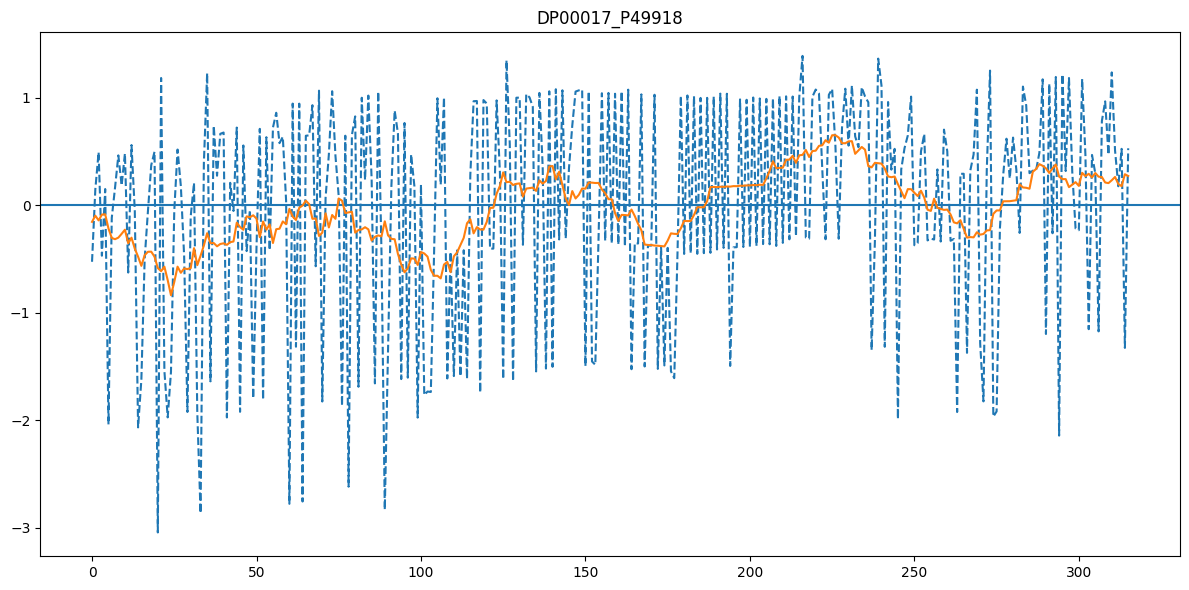

In [ ]:
seq = "MSDASLRSTSTMERLVARGTFPVLVRTSACRSLFGPVDHEELSRELQARLAELNAEDQNRWDYDFQQDMPLRGPGRLQWTEVDSDSVPAFYRETVQVGRCRLLLAPRPVAVAVAVSPPLEPAAESLDGLEEAPEQLPSVPVPAPASTPPPVPVLAPAPAPAPAPVAAPVAAPVAVAVLAPAPAPAPAPAPAPAPVAAPAPAPAPAPAPAPAPAPAPDAAPQESAEQGANQGQRGQEPLADQLHSGISGRPAAGTAAASANGAAIKKLSGPLISDFFAKRKRSAPEKSSGDVPAPCPSPSAAPGVGSVEQTPRKRLR"
print(seq)
pdb_id = "DP00017"
chain_id = "P49918"

pred, pred_smooth = iupred(seq)  # prediction

fig, ax = plt.subplots(figsize=(12, 6))
ax.set_title("{}_{}".format(pdb_id, chain_id))
ax.axhline()
ax.plot(np.arange(len(seq)), pred, ls='--')
ax.plot(np.arange(len(seq)), pred_smooth, ls='-')
plt.tight_layout()  # Remove figure padding
plt.savefig(path + '/figures/iupred_{}_{}.png'.format(pdb_id, chain_id), dpi=300, bbox_inches='tight')

выше 0.5 = disorder  
ниже 0.5 = ordered

- где линия поднимается или долго держится на одном уровне: там меняется склонность участка к disorder

- где сплошная линия образует длинный регион: это потенциально биологически значимый участок

- где только один резкий пик: возможно шум